# Sistema de Scorign de Riesgo Crediticio con Explicabilidad mediante LLM

# Conexión de Drive y SNOWFLAKE. Asi como importación de las principales librerias


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
drive.mount('/content/drive')

ModuleNotFoundError: No module named 'google.colab'

In [ ]:
!pip install snowflake-connector-python -q
import snowflake.connector

import os
from getpass import getpass

SNOWFLAKE_USER = os.environ.get('SNOWFLAKE_USER') or input('Usuario Snowflake: ')
SNOWFLAKE_PASSWORD = os.environ.get('SNOWFLAKE_PASSWORD') or getpass('Password Snowflake: ')
SNOWFLAKE_ACCOUNT = os.environ.get('SNOWFLAKE_ACCOUNT') or input('Account Snowflake: ')

conn=snowflake.connector.connect(user=SNOWFLAKE_USER, password=SNOWFLAKE_PASSWORD, account=SNOWFLAKE_ACCOUNT, database='TFM_DB', schema='PUBLIC', warehouse='COMPUTE_WH')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 15.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.0/105.0 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 39.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 kB 6.0 MB/s eta 0:00:00


In [ ]:
query= "SELECT * FROM CLIENTES_HISTORICOS"
df=pd.read_sql(query,conn)
df=df.rename(columns={'DEFAULT_PAYMENT':'default payment next month'})

/tmp/ipykernel_1380/2792300652.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df=pd.read_sql(query,conn)


In [ ]:
print(f"Filas:{len(df)}")
print(f"columnas: {len(df.columns)}")
print()
print("Columnas disponibles:")
print(df.columns.tolist())
print("Tipos de datos:")
print(df.dtypes)
print()
print("Valores nulos:")
print(df.isnull().sum())

Filas:30000
columnas: 24

Columnas disponibles:
['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']
Tipos de datos:
LIMIT_BAL                     float64
SEX                             int64
EDUCATION                       int64
MARRIAGE                        int64
AGE                             int64
PAY_0                           int64
PAY_2                           int64
PAY_3                           int64
PAY_4                           int64
PAY_5                           int64
PAY_6                           int64
BILL_AMT1                     float64
BILL_AMT2                     float64
BILL_AMT3                     float64
BILL_AMT4                     float64
BILL_AMT5                     float64
BILL_AMT6                     float64
PAY

### El conjunto de datos presenta 30.000 registros y 25 columnas( 23 variables predictoras, un identificador y la variable objetivo), sin valores nulos en ninguna columna, ademas que todas son varibales numericas.

## Estudio Exprloratio de Datos(EDA)

In [ ]:
print("Distribucion de la variable objetivo:")
print(df["default payment next month"].value_counts())
print()
print("En porcentaje:")
print(df["default payment next month"].value_counts(normalize=True).round(3)*100)

Distribucion de la variable objetivo:
default payment next month
0    23364
1     6636
Name: count, dtype: int64

En porcentaje:
default payment next month
0    77.9
1    22.1
Name: proportion, dtype: float64


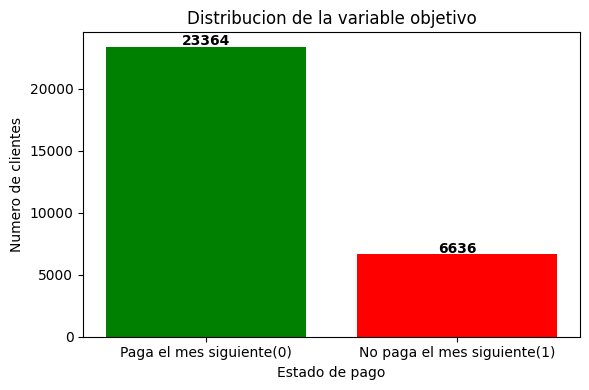

In [ ]:
labels = ['Paga el mes siguiente(0)','No paga el mes siguiente(1)']
valores = df['default payment next month'].value_counts()

plt.figure(figsize=(6,4))
plt.bar(labels,valores, color=['green', 'red'])
plt.title('Distribucion de la variable objetivo')
plt.ylabel('Numero de clientes')
plt.xlabel('Estado de pago')
for i, v in enumerate(valores):
  plt.text(i, v + 150, str(v), ha='center', fontweight='bold')
  plt.tight_layout()
plt.show()

### La variable objetivo presenta un desbalanceo entre clases, el 77,9% de los clientes(23.364) pagaron correctamente, mientras que el restante 22,1% incurrieron  en impago. Debemos tener en cuenta este desbalanceo a la hora de modelizar, utilizando tecnicas como la ponderacion de clases, para asi evitar que los modelos favorezcan sistematicamente a la clase mayoritaria.

Analisis de las variables demograficas


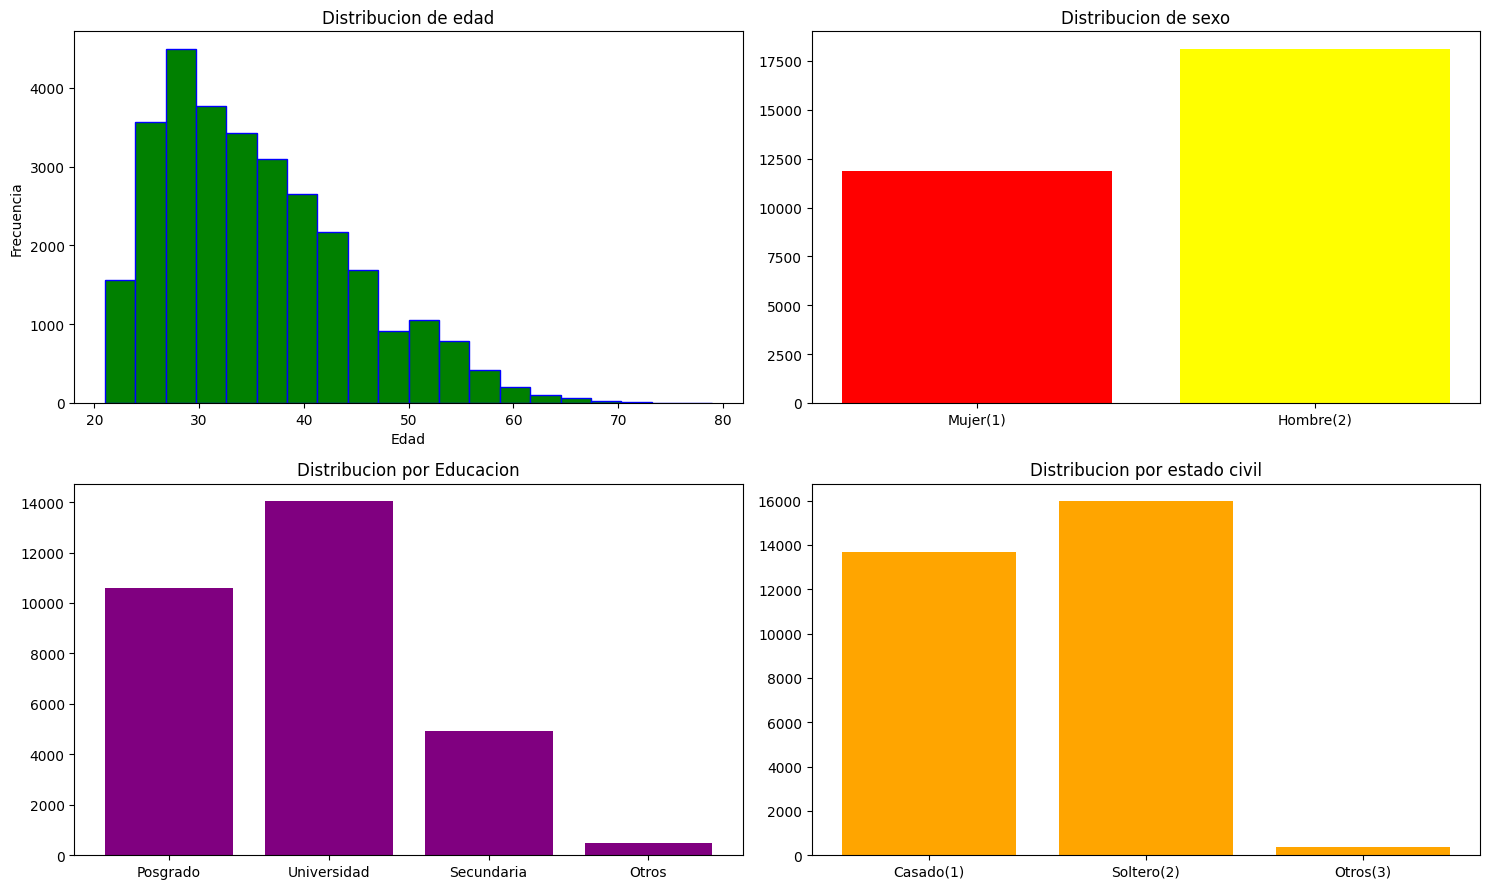

In [ ]:
fig, axes = plt.subplots(2,2, figsize=(15,9))

# EDAD

axes[0,0].hist(df['AGE'], bins=20, color='green',edgecolor='blue')
axes[0,0].set_title('Distribucion de edad')
axes[0,0].set_xlabel('Edad')
axes[0,0].set_ylabel('Frecuencia')

# SEXO

axes[0,1].bar(['Mujer(1)', 'Hombre(2)'], df['SEX'].value_counts().sort_index(), color=['red', 'yellow'])
axes[0,1].set_title('Distribucion de sexo')

# Educacion

axes[1,0].bar(['Posgrado', 'Universidad', 'Secundaria', 'Otros'], df['EDUCATION'].value_counts().sort_index().iloc[:4],color='Purple')
axes[1,0].set_title('Distribucion por Educacion')

# Estado civil corregido

marriage_counts = df['MARRIAGE'].value_counts().sort_index()
axes[1,1].bar(['Casado(1)','Soltero(2)','Otros(3)'], [marriage_counts.get(1,0), marriage_counts.get(2,0),marriage_counts.get(3,0)], color='orange')
axes[1,1].set_title('Distribucion por estado civil')

plt.tight_layout()
plt.show()



### La mayoria de los clientes se situan entre 25 y 35 años, esta compuesta mayoritariamente por hombres(60%), con respecto al nuvel educativo, predominan los clientes con estudios secundarios y universitarios.

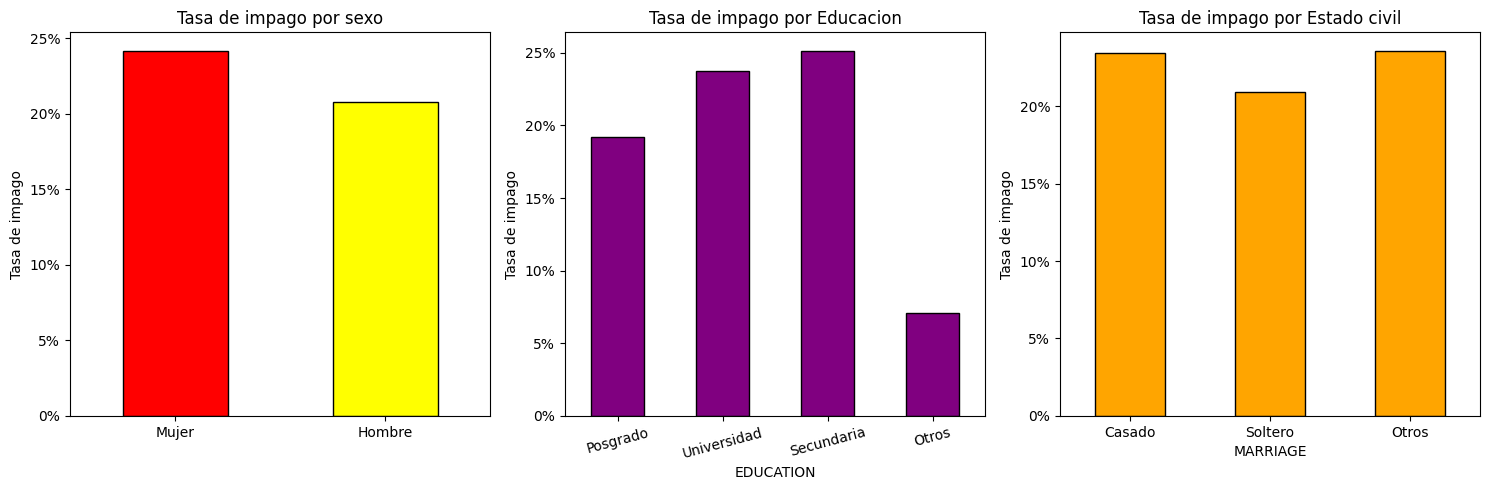

In [ ]:
# Tasa de impago por variable demografica

fig, axes = plt.subplots(1,3, figsize=(15,5))

# Por sexo

df.groupby('SEX')['default payment next month'].mean().plot(kind='bar', ax=axes[0], color=['red', 'yellow'], edgecolor='black')
axes[0].set_title('Tasa de impago por sexo')
axes[0].set_xlabel('')
axes[0].set_xticklabels(['Mujer', 'Hombre'], rotation=0)
axes[0].set_ylabel('Tasa de impago')
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))

# Por educacion

df.groupby('EDUCATION')['default payment next month'].mean().iloc[:4].plot(kind='bar', ax=axes[1], color=['purple'], edgecolor='black')
axes[1].set_title('Tasa de impago por Educacion')
axes[1].set_xticklabels(['Posgrado', 'Universidad','Secundaria','Otros'], rotation=15)
axes[1].set_ylabel('Tasa de impago')
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))

# Pos estado civil

df.groupby('MARRIAGE')['default payment next month'].mean().iloc[:3].plot(kind='bar', ax=axes[2], color=['orange'], edgecolor='black')
axes[2].set_title('Tasa de impago por Estado civil')
axes[2].set_xticklabels(['Casado', 'Soltero','Otros'], rotation=0)
axes[2].set_ylabel('Tasa de impago')
axes[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))

plt.tight_layout()
plt.show()



### Los clientes con menor nivel educativo presentan tasos de impago mas altas, asi como las muujeres.

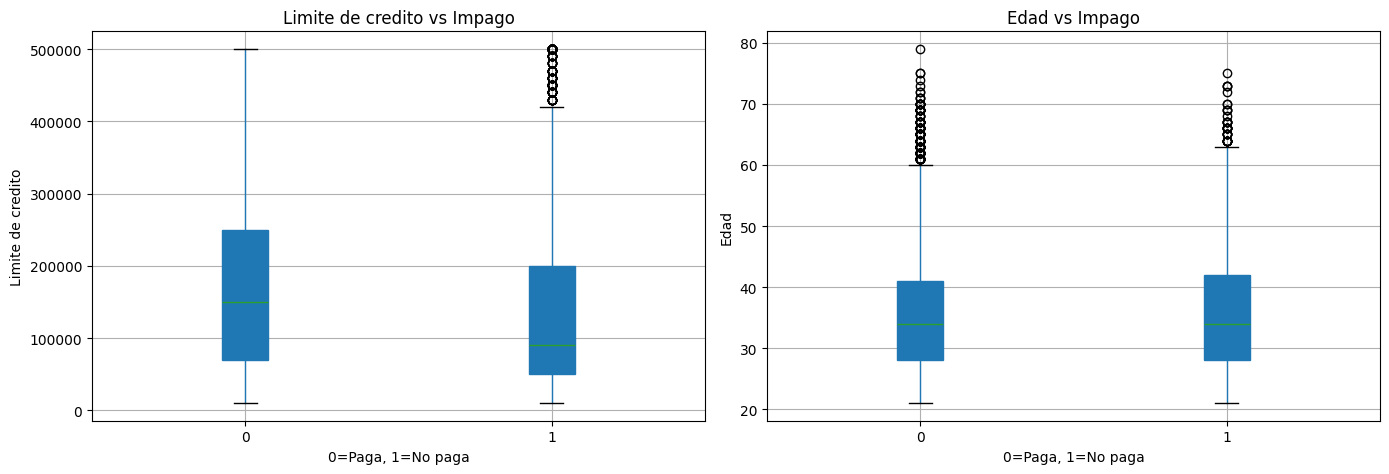

In [ ]:
# Limite de credito y edad vs impago
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Limite de credito por grupo

df.boxplot(column= 'LIMIT_BAL', by='default payment next month', ax= axes[0], patch_artist=True)
axes[0].set_title('Limite de credito vs Impago')
axes[0].set_xlabel('0=Paga, 1=No paga')
axes[0].set_ylabel('Limite de credito')

# Edad por grupo

df.boxplot(column='AGE', by='default payment next month', ax=axes[1],patch_artist=True)
axes[1].set_title('Edad vs Impago')
axes[1].set_xlabel('0=Paga, 1=No paga')
axes[1].set_ylabel('Edad')

plt.suptitle('')
plt.tight_layout()
plt.show()

### Observamos como en el primer grafico, a mayor limite de credito, mayor pago. En cambio en el segundo grafico observamos que es un poco mas complicado sacar conclusiones por el parecido de edad(en media) de los que pagan y de los que no

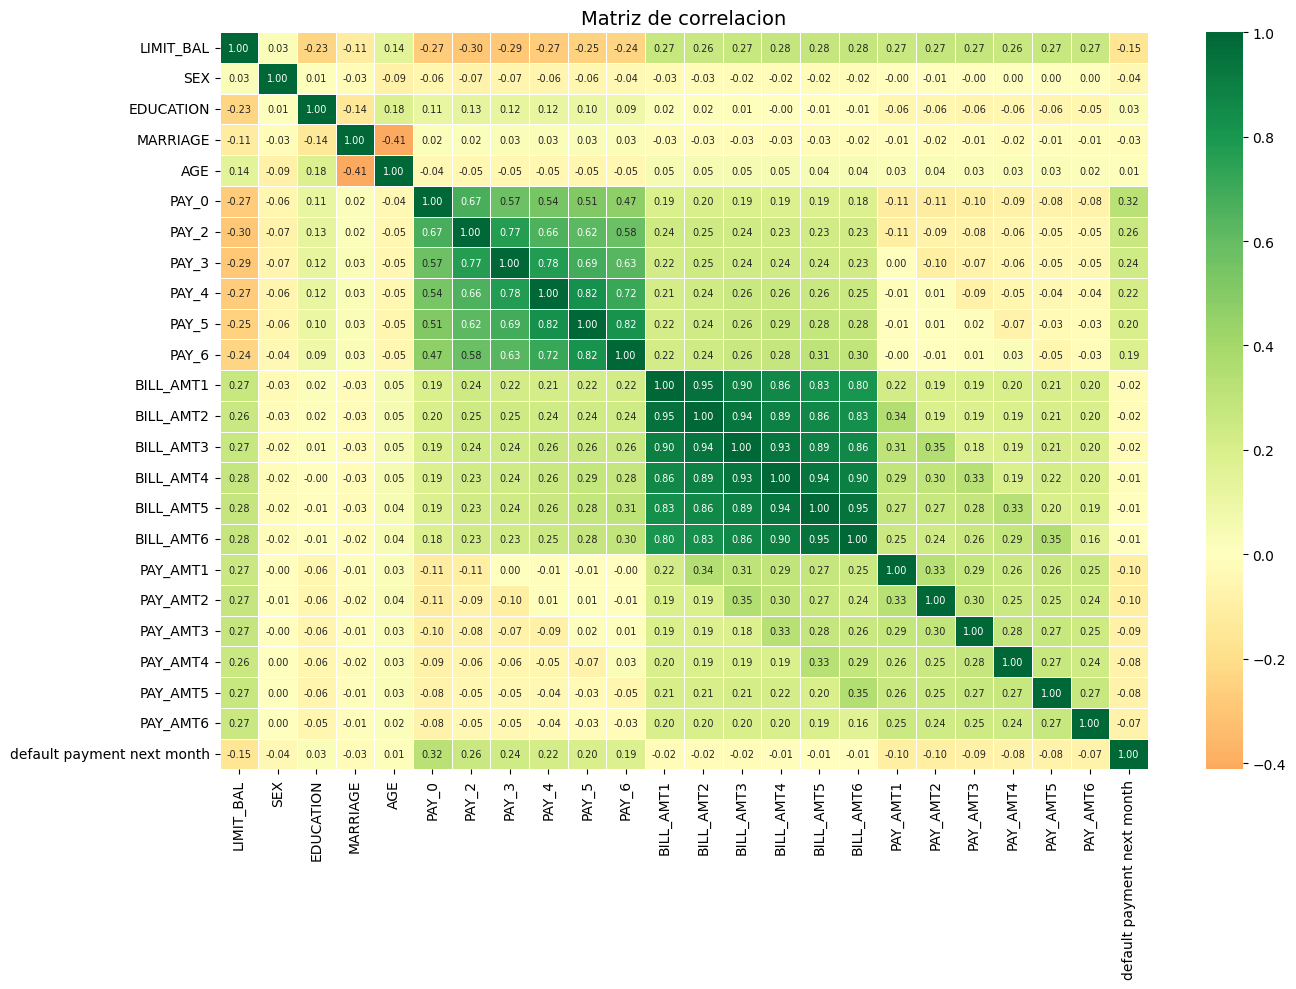

In [ ]:
# Matriz de correlacion

plt.figure(figsize=(14,10))
correlacion = df.corr()

sns.heatmap(correlacion, annot=True, fmt='.2f', cmap='RdYlGn', center=0, linewidths=0.5, annot_kws={'size': 7})

plt.title('Matriz de correlacion', fontsize=14)
plt.tight_layout()
plt.show()

### Vemos como las variables(PAY_0 a PAY_6) estan fuertemente correlacionadas entre si, lo que nos lleva a la conclusion de que el comportamiento de pago de un cliente es consistente en el tiempo. Sucede algo similar con el importe de la factura(BILL_AMT1-BILL_AMT6).

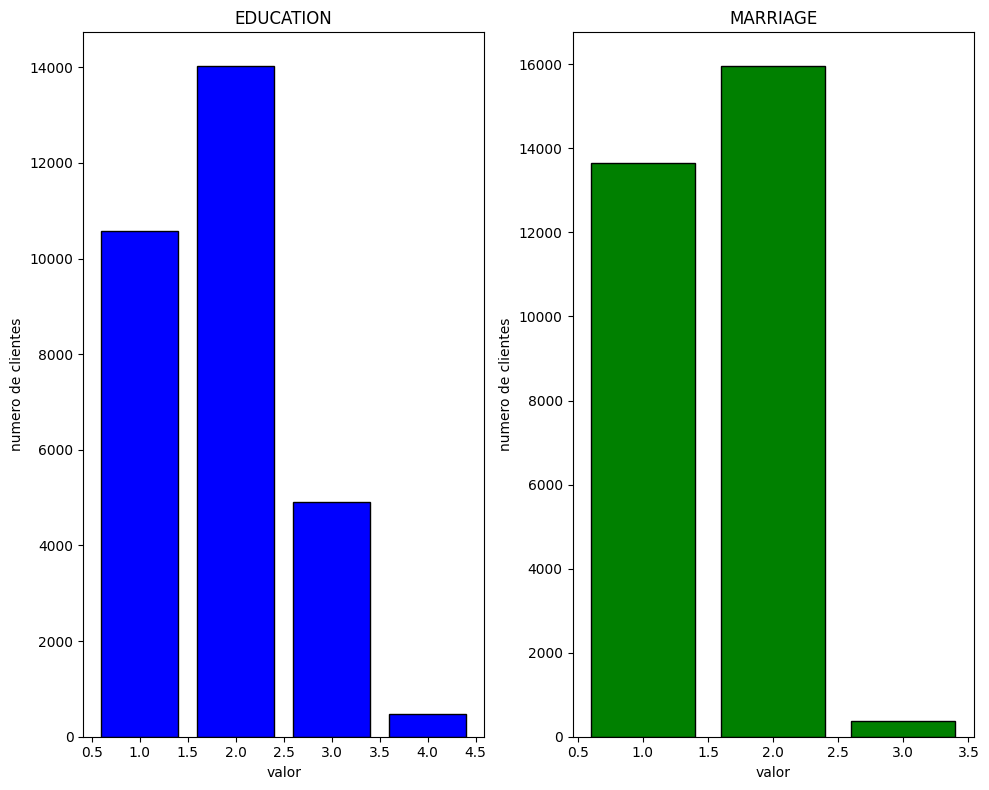

In [ ]:
fig, axes = plt.subplots(1,2, figsize=(10,8))

# EDUCATION
axes[0].bar(df['EDUCATION'].value_counts().sort_index().index, df['EDUCATION'].value_counts().sort_index().values, color='blue', edgecolor='black')
axes[0].set_title('EDUCATION')
axes[0].set_ylabel('numero de clientes')
axes[0].set_xlabel('valor')

# MARRIAGE
axes[1].bar(df['MARRIAGE'].value_counts().sort_index().index, df['MARRIAGE'].value_counts().sort_index().values, color='green', edgecolor='black')
axes[1].set_title('MARRIAGE')
axes[1].set_ylabel('numero de clientes')
axes[1].set_xlabel('valor')

plt.tight_layout()
plt.show()

In [ ]:
print('Valores unicos en EDUCATION')
print(df['EDUCATION'].value_counts().sort_index())
print()
print('Valores unicos en MARRIAGE')
print(df['MARRIAGE'].value_counts().sort_index())

Valores unicos en EDUCATION
EDUCATION
1    10585
2    14030
3     4917
4      468
Name: count, dtype: int64

Valores unicos en MARRIAGE
MARRIAGE
1    13659
2    15964
3      377
Name: count, dtype: int64


In [ ]:
resumen = df.describe().round(2).T
resumen.to_csv('/content/drive/MyDrive/TFM/resumen_estadisticas.csv')
print(resumen)

                              count       mean        std       min       25%  \
LIMIT_BAL                   30000.0  166808.66  127584.47   10000.0  50000.00   
SEX                         30000.0       1.60       0.49       1.0      1.00   
EDUCATION                   30000.0       1.84       0.74       1.0      1.00   
MARRIAGE                    30000.0       1.56       0.52       1.0      1.00   
AGE                         30000.0      35.49       9.22      21.0     28.00   
PAY_0                       30000.0      -0.02       1.12      -2.0     -1.00   
PAY_2                       30000.0      -0.13       1.20      -2.0     -1.00   
PAY_3                       30000.0      -0.17       1.20      -2.0     -1.00   
PAY_4                       30000.0      -0.22       1.17      -2.0     -1.00   
PAY_5                       30000.0      -0.27       1.13      -2.0     -1.00   
PAY_6                       30000.0      -0.29       1.15      -2.0     -1.00   
BILL_AMT1                   

## Tratamiento de valores anomalos

In [ ]:
# Valores 0, 5 y 6 de EDUCATION loos ponemos en otros
df['EDUCATION'] = df['EDUCATION'].replace({0:4, 5:4, 6:4})

# Valores 0 de MARRIAGE los ponemos en otros
df['MARRIAGE'] = df['MARRIAGE'].replace({0:3})

print('EDUCATION despues:')
print(df['EDUCATION'].value_counts().sort_index())
print()
print('MARRIAGE despues:')
print(df['MARRIAGE'].value_counts().sort_index())

EDUCATION despues:
EDUCATION
1    10585
2    14030
3     4917
4      468
Name: count, dtype: int64

MARRIAGE despues:
MARRIAGE
1    13659
2    15964
3      377
Name: count, dtype: int64


### Las categorias 0,5 y 6 de EDUCATION y la categoria 0 de MARRIAGE son muy poco representativas, por lo que reclasificare a las categorias 'Otros'. Si bien es cierto que en el caso de MARRIAGE solo pueden haber dos opciones: Soltero o Casado, he decidido dejar la categoria OTROS por su poca cantidad y no retocar tanto el modelo.

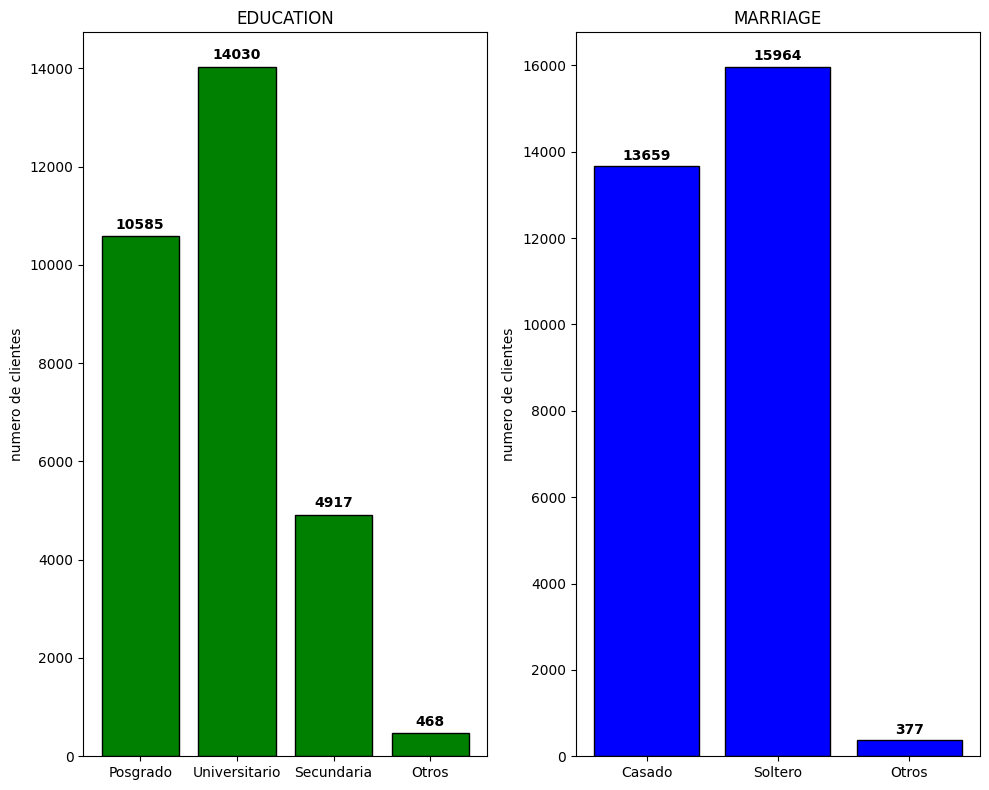

In [ ]:
fig, axes = plt.subplots(1,2, figsize=(10,8))
#EDUCATION
education_labels= {1: 'Posgrado', 2: 'Universitario', 3: 'Secundaria', 4: 'Otros'}
education_counts = df['EDUCATION'].value_counts().sort_index()
axes[0].bar([education_labels[i] for  i in education_counts.index], education_counts.values, color='green', edgecolor='black')
axes[0].set_title('EDUCATION')
axes[0].set_ylabel('numero de clientes')
for i, v in enumerate(education_counts.values):
  axes[0].text(i, v + 150, str(v), ha='center', fontweight='bold')

# MARRIAGE

marriage_labels ={1: 'Casado', 2: 'Soltero', 3: 'Otros'}
marriage_counts = df['MARRIAGE'].value_counts().sort_index()
axes[1].bar([marriage_labels[i] for i in marriage_counts.index], marriage_counts.values, color='blue', edgecolor='black')
axes[1].set_title('MARRIAGE')
axes[1].set_ylabel('numero de clientes')
for i, v in enumerate(marriage_counts.values):
  axes[1].text(i, v + 150, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()







## Tratamiento de Outliers


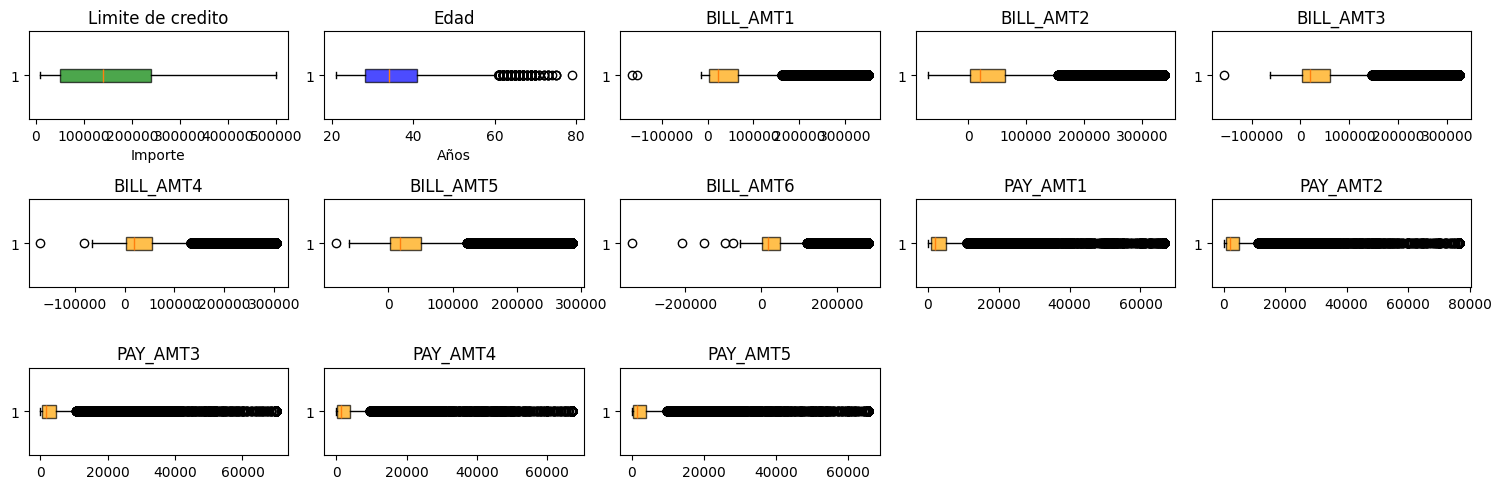

In [ ]:

fig, axes = plt.subplots(3,5, figsize=(15,5))

# Limite de credito
axes[0,0].boxplot(df['LIMIT_BAL'], vert=False, patch_artist=True, boxprops=dict(facecolor='green', alpha=0.7))
axes[0,0].set_title('Limite de credito')
axes[0,0].set_xlabel('Importe')

# edad
axes[0,1].boxplot(df['AGE'], vert=False, patch_artist=True, boxprops=dict(facecolor='blue', alpha=0.7))
axes[0,1].set_title('Edad')
axes[0,1].set_xlabel('Años')

# Factura septiembre
variables = [f'BILL_AMT{i}' for i in range(1,7)] +[f'PAY_AMT{i}' for i in range(1,7)]
for i, var in enumerate(variables):
  fila= (i+2) // 5
  col = (i+2) % 5
  axes[fila,col].boxplot(df[var], vert=False, patch_artist=True, boxprops=dict(facecolor='orange', alpha=0.7))
  axes[fila,col].set_title(var)
axes[2,3].set_visible(False)
axes[2,4].set_visible(False)

plt.tight_layout()
plt.show()


### En el boxplot de Limite de credito y de los importes de factura y pago observamos valores extremos que no podemos eliminar ya que pueden ser clientes con alto poder adquisitivo y por ende son valores reales y no errores. Igualmente, para limitar su impacto, aplicamos la winsorizacion al percentil 99 para asi limitar el impacto de los valores extremos y evitamos descartar informacion posiblemente relevante.

In [ ]:
from scipy.stats import mstats
# a winsorizar
v_winks = ['LIMIT_BAL'] + [f'BILL_AMT{i}' for i in range(1,7)] + [f'PAY_AMT{i}' for i in range(1,7)]
for var in v_winks:
  df[var] = mstats.winsorize(df[var], limits=[0,0.01])

print(df[v_winks].describe().round(2))

       LIMIT_BAL  BILL_AMT1  BILL_AMT2  BILL_AMT3  BILL_AMT4  BILL_AMT5  \
count   30000.00   30000.00   30000.00   30000.00   30000.00   30000.00   
mean   166808.66   50401.56   48355.50   46144.64   42476.35   39548.53   
std    127584.47   69333.22   66825.49   64382.61   60087.26   56615.50   
min     10000.00 -165580.00  -69777.00 -157264.00 -170000.00  -81334.00   
25%     50000.00    3558.75    2984.75    2666.25    2326.75    1763.00   
50%    140000.00   22381.50   21200.00   20088.50   19052.00   18104.50   
75%    240000.00   67091.00   64006.25   60164.75   54506.00   50190.50   
max    500000.00  350110.00  337495.00  325024.00  304997.00  285868.00   

       BILL_AMT6  PAY_AMT1  PAY_AMT2  PAY_AMT3  PAY_AMT4  PAY_AMT5  PAY_AMT6  
count   30000.00  30000.00  30000.00  30000.00  30000.00  30000.00  30000.00  
mean    38134.61   5029.47   5088.72   4555.45   4246.42   4200.11   4553.85  
std     55521.34   9430.27  10341.62   9560.27   9272.34   9063.24  11039.17  
min   -3

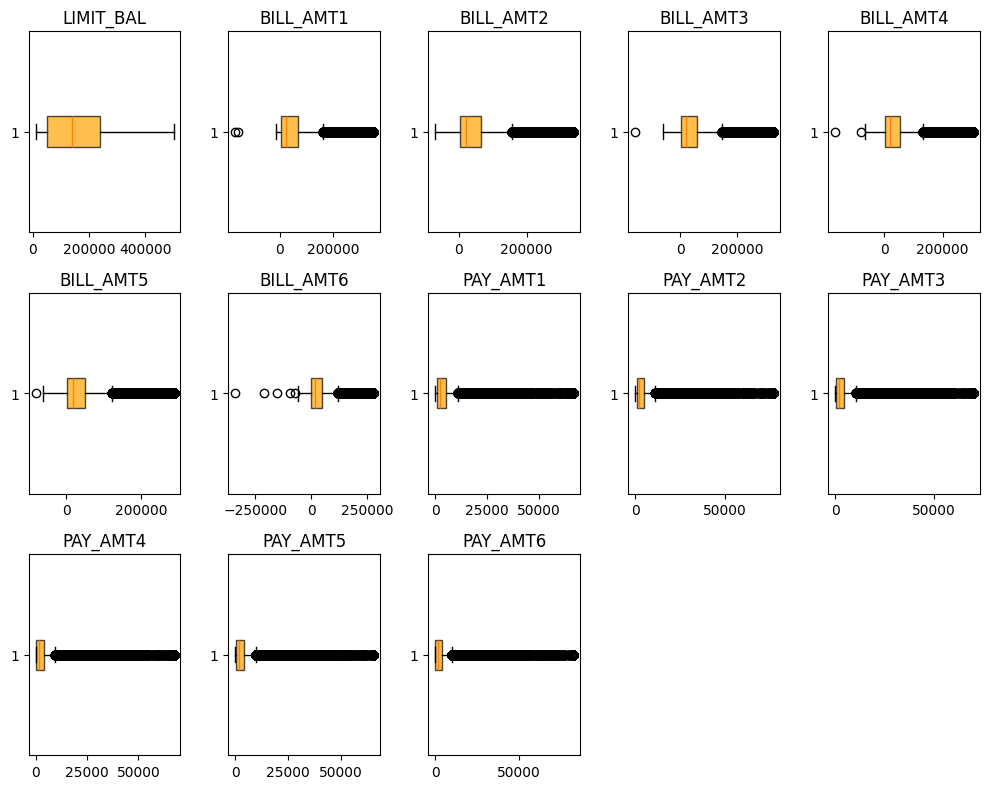

In [ ]:
v_check= ['LIMIT_BAL'] + [f'BILL_AMT{i}' for i in range(1,7)] + [f'PAY_AMT{i}' for i in range(1,7)]

fig, axes = plt.subplots(3,5, figsize=(10,8))

for i, var in enumerate(v_check):
  fila= i// 5
  col= i % 5
  axes[fila,col].boxplot(df[var], vert=False, patch_artist=True, boxprops=dict(facecolor='orange', alpha=0.7))
  axes[fila,col].set_title(var)

axes[2,3].set_visible(False)
axes[2,4].set_visible(False)

plt.tight_layout()
plt.show()

## Creación de nuevas variables


In [ ]:
# Ratio de uso del credito
df['ratio_uso_credito']= df['BILL_AMT1']/ (df['LIMIT_BAL']+1)

# Total deuda acumulada
df['total_deuda']= df[[f'BILL_AMT{i}' for i in range(1,7)]].sum(axis=1)

# total pagado
df['total_pagado']= df[[f'PAY_AMT{i}' for i in range(1,7)]].sum(axis=1)

# Ratio pago/deuda
df['ratio_pago_deuda']= df['total_pagado']/ (df['total_deuda']+ 1)

# Tendencia de pago
df['tendencia_pago']= df['PAY_0']- df['PAY_6']

print(df[['ratio_uso_credito', 'total_deuda', 'total_pagado', 'ratio_pago_deuda', 'tendencia_pago']].describe().round(2))

       ratio_uso_credito  total_deuda  total_pagado  ratio_pago_deuda  \
count           30000.00     30000.00      30000.00          30000.00   
mean                0.42    265061.18      27674.02             16.97   
std                 0.41    355314.36      36617.77            836.27   
min                -0.62   -336259.00          0.00           -589.00   
25%                 0.02     28688.00       6679.75              0.04   
50%                 0.31    126311.00      14383.00              0.09   
75%                 0.82    342626.50      33503.50              0.57   
max                 6.45   1882997.00     420185.00          82615.00   

       tendencia_pago  
count        30000.00  
mean             0.27  
std              1.17  
min             -7.00  
25%              0.00  
50%              0.00  
75%              1.00  
max              7.00  


### Variables creadas

- Ratio uso credito: proporcion del limite de credito utilizado por el cliente.
- Total deuda: deuda acumulada en los ultimos 6 meses
- Total pagado: Total pagado por el cliente en los ultimos 6 meses.
- ratio pago/deuda: Proporcion de deuda cubierta con los pagos realizados.
- tendencia de pago: variacion de la deuda cubierta con los pagos realizados.

## Preparación de datos para el modelo

In [ ]:
from sklearn.model_selection import train_test_split

# separar variables predictoras y variables objetivo
X = df.drop('default payment next month', axis=1)
Y = df['default payment next month']

# Split 80% para entrenamiento y 20% para test
X_train, X_test, Y_train, Y_test = train_test_split(X,Y, test_size= 0.2, random_state= 42, stratify=Y)
print(f'Total filas: {len(df)}')
print(f'Entrenamiento: {len(X_train)} filas ({len(X_train)/len(df)*100:.0f}%)')
print(f'Test: {len(X_test)} filas ({len(X_test)/len(df)*100:.0f}%)')
print(f"Distribucion objetivo en entrenamiento:")
print(Y_train.value_counts(normalize=True).round(3)*100)
print(f"Distribucion objetivo en test:")
print(Y_test.value_counts(normalize=True).round(3)*100)

Total filas: 30000
Entrenamiento: 24000 filas (80%)
Test: 6000 filas (20%)
Distribucion objetivo en entrenamiento:
default payment next month
0    77.9
1    22.1
Name: proportion, dtype: float64
Distribucion objetivo en test:
default payment next month
0    77.9
1    22.1
Name: proportion, dtype: float64


## Regresión Logistica

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.preprocessing import StandardScaler

#escalado de datos
scaler= StandardScaler()
X_train_scaled= scaler.fit_transform(X_train)
X_test_scaled= scaler.transform(X_test)

# entrenar modelo
lr= LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
lr.fit(X_train_scaled, Y_train)

# prediccion
y_pred_lr= lr.predict(X_test_scaled)

# resultado
print("Regresion logistica")
print(classification_report(Y_test, y_pred_lr))
print(f"ROC-AUC: {roc_auc_score(Y_test, y_pred_lr):.4f}")


Regresion logistica
              precision    recall  f1-score   support

           0       0.87      0.70      0.78      4673
           1       0.37      0.63      0.47      1327

    accuracy                           0.68      6000
   macro avg       0.62      0.66      0.62      6000
weighted avg       0.76      0.68      0.71      6000

ROC-AUC: 0.6635


### Obtiene un ROC-AUC de 0,66 y un recall del 63%( de 100 clientes, detecta correctamente a 63 de ellos) sobre la clase de imago, con un accuracy del 68%( acierta en 68 de 100 casos.

## XGBoost

In [ ]:
from xgboost import XGBClassifier

# entrenar modelo
escala= Y_train.value_counts()[0]/Y_train.value_counts()[1]

xgb= XGBClassifier(scale_pos_weight= escala, random_state=42,eval_metric='auc',n_estimators=200,max_depth=5,learning_rate=0.1)
xgb.fit(X_train, Y_train)

# prediccion
Y_pred_xgb= xgb.predict(X_test)

print(classification_report(Y_test,Y_pred_xgb))
print(f'ROC-AUC: {roc_auc_score(Y_test,xgb.predict_proba(X_test)[:,1]):.4f}')


              precision    recall  f1-score   support

           0       0.88      0.81      0.84      4673
           1       0.47      0.61      0.53      1327

    accuracy                           0.76      6000
   macro avg       0.68      0.71      0.69      6000
weighted avg       0.79      0.76      0.77      6000

ROC-AUC: 0.7726


### Obtiene un ROC-AUC de 0,77 y un recall del 61%( de 100 clientes, detecta correctamente a 61 de ellos) sobre la clase de imago, con un accuracy del 76%( acierta en 76 de 100 casos).

## LightGBM

In [ ]:
from lightgbm import LGBMClassifier

# entrenar modelo
lgbm= LGBMClassifier(scale_pos_weight=escala, random_state=42, n_estimators=200,max_depth=5,learning_rate=0.1)
lgbm.fit(X_train, Y_train)

#Prediccion
Y_pred_lgbm= lgbm.predict(X_test)

print(classification_report(Y_test,Y_pred_lgbm))
print(f'ROC-AUC: {roc_auc_score(Y_test,lgbm.predict_proba(X_test)[:,1]):.4f}')


[LightGBM] [Info] Number of positive: 5309, number of negative: 18691
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002814 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4272
[LightGBM] [Info] Number of data points in the train set: 24000, number of used features: 28
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.221208 -> initscore=-1.258639
[LightGBM] [Info] Start training from score -1.258639
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain

### Obtiene un ROC-AUC de 0,77 y un recall del 61%( de 100 clientes, detecta correctamente a 61 de ellos) sobre la clase de imago, con un accuracy del 76%( acierta en 76 de 100 casos). La diferencia con XGBoost, es que LightGBM tiene un entrenamiento mas rapido.

## Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# entrenar
rf= RandomForestClassifier(n_estimators=200, max_depth=5, class_weight='balanced', random_state=42)
rf.fit(X_train, Y_train)

 # prediccion
Y_pred_rf= rf.predict(X_test)

print(classification_report(Y_test,Y_pred_rf))
print(f'ROC-AUC: {roc_auc_score(Y_test,rf.predict_proba(X_test)[:,1]):.4f}')

              precision    recall  f1-score   support

           0       0.88      0.84      0.86      4673
           1       0.51      0.58      0.54      1327

    accuracy                           0.78      6000
   macro avg       0.69      0.71      0.70      6000
weighted avg       0.79      0.78      0.79      6000

ROC-AUC: 0.7718


### Obtiene un ROC-AUC de 0,76 y un recall del 59%( de 100 clientes, detecta correctamente a 59 de ellos) sobre la clase de imago, con un accuracy del 77%( acierta en 77 de 100 casos).

In [ ]:
from sklearn.utils import resample

# Separar clases
X_train_0 = X_train[Y_train == 0]
X_train_1 = X_train[Y_train == 1]
Y_train_0 = Y_train[Y_train == 0]
Y_train_1 = Y_train[Y_train == 1]

print(f'Antes Pagan(0): {len(X_train_0)}')
print(f'Antes no pagan(1): {len(X_train_1)}')

# Oversampling

X_train_1_over = resample(X_train_1, replace=True, n_samples=len(X_train_0),random_state=42)
Y_train_1_over = resample(Y_train_1, replace=True, n_samples=len(X_train_0),random_state=42)

# combinar clases
X_train_bal = pd.concat([X_train_0, X_train_1_over])
Y_train_bal = pd.concat([Y_train_0, Y_train_1_over])

print(f'Pagan(0):{(Y_train_bal ==0).sum()}')
print(f'No pagan(1):{(Y_train_bal== 1).sum()}')
print(f'Total filas: {len(Y_train_bal)}')

Antes Pagan(0): 18691
Antes no pagan(1): 5309
Pagan(0):18691
No pagan(1):18691
Total filas: 37382


In [ ]:
#LightGBM con oversampling
lgbm_bal= LGBMClassifier(random_state=42, n_estimators=200,max_depth=5,learning_rate=0.1, verbose=-1)
lgbm_bal.fit(X_train_bal, Y_train_bal)

#Prediccion
Y_pred_lgbm_bal= lgbm_bal.predict(X_test)

print(classification_report(Y_test,Y_pred_lgbm_bal))
print(f'ROC-AUC: {roc_auc_score(Y_test,lgbm_bal.predict_proba(X_test)[:,1]):.4f}')

              precision    recall  f1-score   support

           0       0.88      0.82      0.84      4673
           1       0.48      0.59      0.53      1327

    accuracy                           0.77      6000
   macro avg       0.68      0.70      0.69      6000
weighted avg       0.79      0.77      0.77      6000

ROC-AUC: 0.7678


### El oversampling de la clase minoritaria no mejora el rendimiento.

## Optimizacion automatica de hiperparametros con libreria OPTUNA

In [ ]:
!pip install optuna -q
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 15.7 MB/s eta 0:00:00


In [ ]:
import optuna
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score

def objective(trial):
  param = {'n_estimators': trial.suggest_int('n_estimators', 100, 500),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3),
        'num_leaves': trial.suggest_int('num_leaves', 20, 100),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 50),
        'scale_pos_weight': escala,
        'random_state': 42,
        'verbose': -1}
  modelo = LGBMClassifier(**param)
  modelo.fit(X_train, Y_train)
  y_pred = modelo.predict_proba(X_test)[:,1]
  return roc_auc_score(Y_test, y_pred)

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=50, show_progress_bar=True)

print(f'ROC-AUC: {study.best_value:.4f}')
print(f'Mejores hiperparametros: {study.best_params}')

  0%|          | 0/50 [00:00<?, ?it/s]

ROC-AUC: 0.7801
Mejores hiperparametros: {'n_estimators': 179, 'max_depth': 8, 'learning_rate': 0.011972052518918553, 'num_leaves': 24, 'min_child_samples': 30}


## LightGBM optimizado

In [ ]:
lgbm_opt = LGBMClassifier(n_estimators=392,max_depth=3,learning_rate= 0.027715825252133043,num_leaves=92, min_child_samples=25,scale_pos_weight=escala,random_state=42,verbose=-1)
lgbm_opt.fit(X_train, Y_train)

Y_pred_opt= lgbm_opt.predict(X_test)

print(classification_report(Y_test,Y_pred_opt))
print(f'ROC-AUC: {roc_auc_score(Y_test,lgbm_opt.predict_proba(X_test)[:,1]):.4f}')

              precision    recall  f1-score   support

           0       0.88      0.81      0.84      4673
           1       0.48      0.61      0.54      1327

    accuracy                           0.77      6000
   macro avg       0.68      0.71      0.69      6000
weighted avg       0.79      0.77      0.78      6000

ROC-AUC: 0.7814


### Tras 50 iteraciones de optimizacion don OPTUNA, LightGBM Obtiene un ROC-AUC de 0,78 y un recall del 61%( de 100 clientes, detecta correctamente a 61 de ellos) sobre la clase de imago, con un accuracy del 77%( acierta en 77 de 100 casos).

## Random Forest optimizado

In [ ]:
from sklearn.ensemble import RandomForestClassifier

def objective_rf(trial):
  param = {'n_estimators': trial.suggest_int('n_estimators', 100, 500),
        'max_depth': trial.suggest_int('max_depth', 3, 10),'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1,10), 'class_weight':'balanced', 'random_state':42}

  modelo = RandomForestClassifier(**param)
  modelo.fit(X_train, Y_train)
  Y_pred = modelo.predict_proba(X_test)[:,1]
  return roc_auc_score(Y_test, Y_pred)
study_rf= optuna.create_study(direction='maximize')
study_rf.optimize(objective_rf, n_trials=50, show_progress_bar=True)

print(f'ROC-AUC: {study_rf.best_value:.4f}')
print(f'Mejores hiperparametros: {study_rf.best_params}')

  0%|          | 0/50 [00:00<?, ?it/s]

ROC-AUC: 0.7788
Mejores hiperparametros: {'n_estimators': 328, 'max_depth': 10, 'min_samples_split': 6, 'min_samples_leaf': 8}


In [ ]:
rf_opt = RandomForestClassifier(n_estimators=409,max_depth=9,min_samples_split=11,min_samples_leaf=10,class_weight='balanced',random_state=42)
rf_opt.fit(X_train, Y_train)

Y_pred_opt= rf_opt.predict(X_test)

print(classification_report(Y_test,Y_pred_opt))
print(f'ROC-AUC: {roc_auc_score(Y_test,rf_opt.predict_proba(X_test)[:,1]):.4f}')

              precision    recall  f1-score   support

           0       0.88      0.84      0.86      4673
           1       0.51      0.58      0.55      1327

    accuracy                           0.78      6000
   macro avg       0.69      0.71      0.70      6000
weighted avg       0.80      0.78      0.79      6000

ROC-AUC: 0.7787


### Tiene peor recall que LightGBM optimizado, nos quedamos con LightGBM optimizado.

### Solo lo hice con estos dos modelos por ser los mas prometedores en el paso anterior


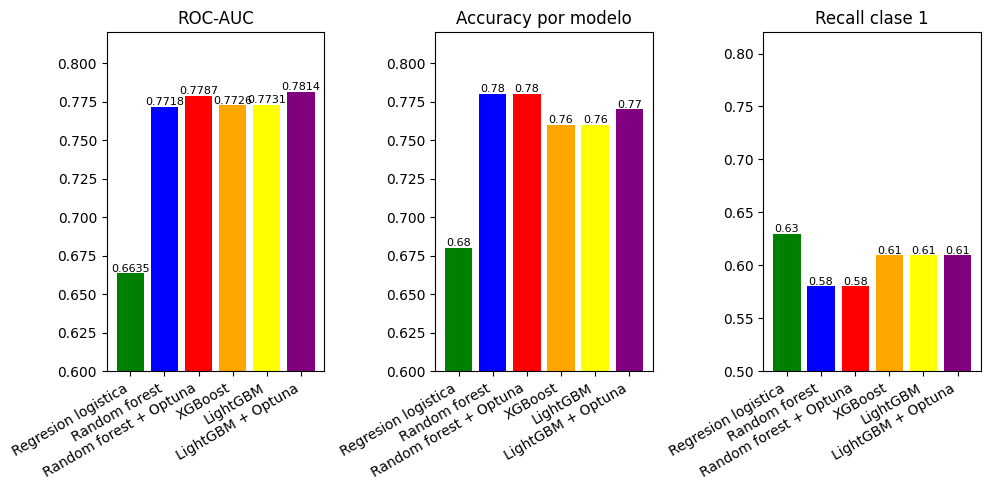

In [ ]:
modelos=['Regresion logistica','Random forest','Random forest + Optuna','XGBoost','LightGBM','LightGBM + Optuna']
roc_auc=[0.6635, 0.7718, 0.7787,0.7726,0.7731,0.7814]
accuracy=[0.68,0.78,0.78,0.76,0.76,0.77]
recall=[0.63,0.58,0.58,0.61,0.61,0.61]

x=range(len(modelos))
fig, axes = plt.subplots(1,3, figsize=(10,5))

#ROC-AUC

axes[0].bar(x, roc_auc, color=['green','blue','red','orange','yellow','purple'])
axes[0].set_title('ROC-AUC')
axes[0].set_xticks(x)
axes[0].set_xticklabels(modelos, rotation=30, ha='right')
axes[0].set_ylim(0.6,0.82)
for i, v in enumerate(roc_auc):
  axes[0].text(i, v + 0.001, f'{v:.4f}', ha='center', fontsize=8)

#Accuracy

axes[1].bar(x, accuracy, color=['green','blue','red','orange','yellow','purple'])
axes[1].set_title('Accuracy por modelo')
axes[1].set_xticks(x)
axes[1].set_xticklabels(modelos, rotation=30, ha='right')
axes[1].set_ylim(0.6,0.82)
for i, v in enumerate(accuracy):
  axes[1].text(i, v + 0.001, f'{v:.2f}', ha='center', fontsize=8)

#Recall clase 1

axes[2].bar(x, recall, color=['green','blue','red','orange','yellow','purple'])
axes[2].set_title('Recall clase 1')
axes[2].set_xticks(x)
axes[2].set_xticklabels(modelos, rotation=30, ha='right')
axes[2].set_ylim(0.5,0.82)
for i, v in enumerate(recall):
  axes[2].text(i, v + 0.001, f'{v:.2f}', ha='center', fontsize=8)

plt.tight_layout()
plt.show()

#

### En conclusion, quien presento mejores resultados por capacidad de discriminacion global(ROC-AUC mas alto) y capacidad de deteccion de clientes en riesgo de impago(recall) es el modelo LightGBM optimizado.

## Analisis de variables SHAP

In [ ]:
!pip install shap -q
import shap

explainer=shap.TreeExplainer(lgbm_opt)
shap_values = explainer.shap_values(X_test)

print(f'Shape:{shap_values.shape}')

Shape:(6000, 28)


/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


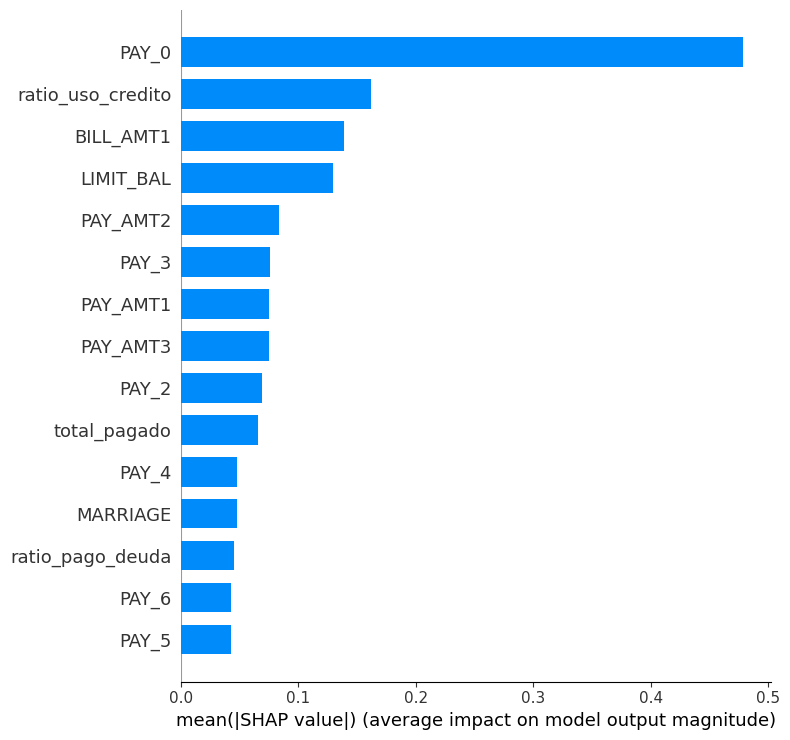

In [ ]:
shap_vals = shap_values[1] if isinstance(shap_values,list) else shap_values
shap.summary_plot(shap_vals, X_test, plot_type='bar',max_display=15)

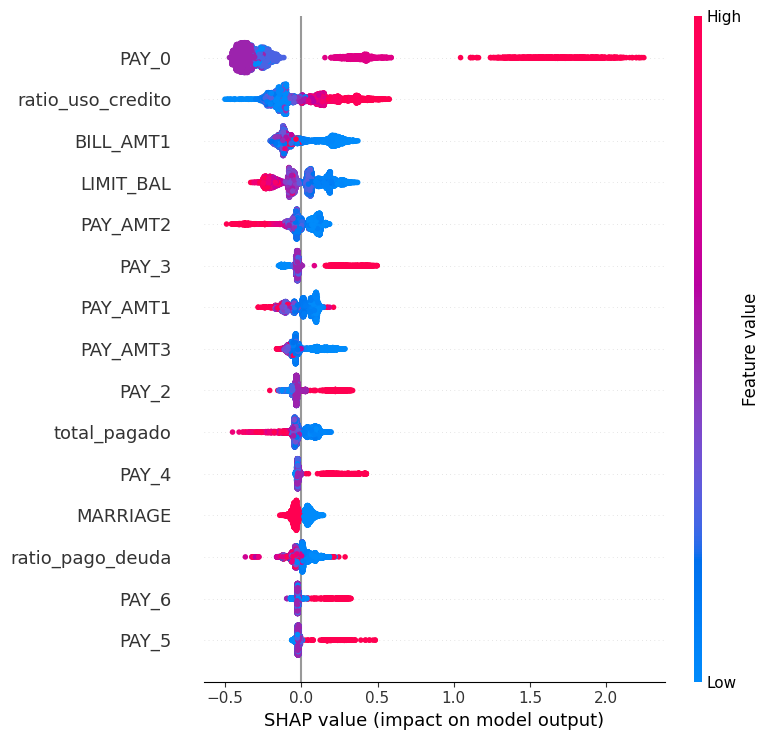

In [ ]:
shap.summary_plot(shap_vals, X_test,max_display=15)

### Vemos como las variables mas relevantes del modelo son:
1) PAY_0( estado del pago mas reciente)
2) ratio_uso_credito
3) BILL_AMT1( importe de la factura mas reciente)



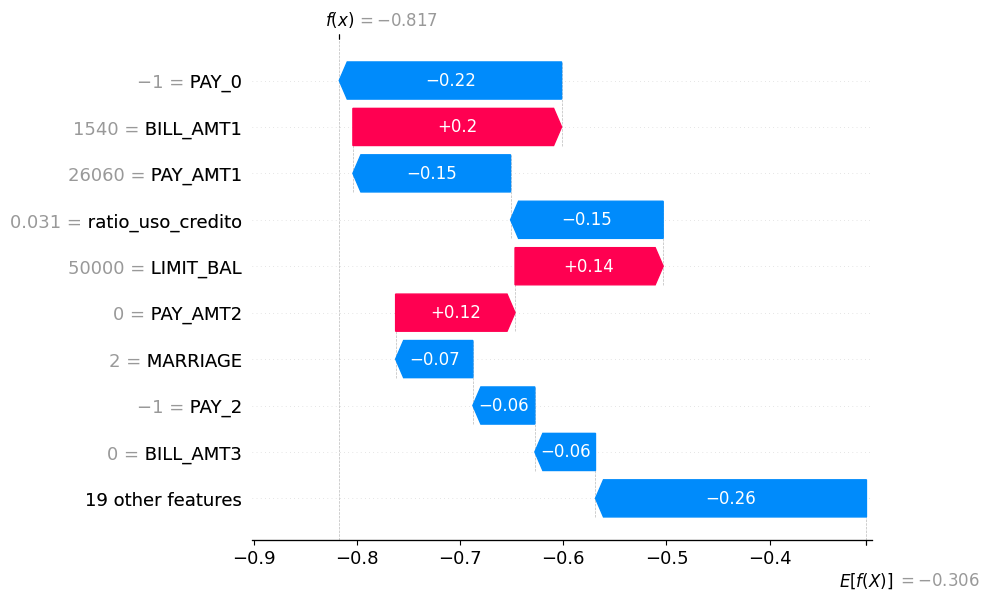

In [ ]:
# SHAP individual
cliente_idx= 0

shap.waterfall_plot(shap.Explanation(values=shap_vals[cliente_idx], base_values=explainer.expected_value,data=X_test.iloc[cliente_idx],feature_names=X_test.columns.tolist()))

### Para este cliente en concreto, el principal factor que reduce su riesgo es un historial de pagos correcto y un uso muy bajo de su limite de credito disponible.

## Union de Modelo con IA Generativa

In [ ]:
# Instalar libreria de gemini
!pip install google-generativeai -q

import google.generativeai as genai
import os
from getpass import getpass

gemini_api_key = os.environ.get('GEMINI_API_KEY') or getpass('Gemini API key: ')
genai.configure(api_key=gemini_api_key)
modelo_llm = genai.GenerativeModel('gemini-3.6-flash')

/usr/local/lib/python3.13/dist-packages/google/colab/_import_hooks/_hook_injector.py:55: FutureWarning: 

All support for the `google.generativeai` package has ended. It will no longer be receiving 
updates or bug fixes. Please switch to the `google.genai` package as soon as possible.
See README for more details:

https://github.com/google-gemini/deprecated-generative-ai-python/blob/main/README.md

  loader.exec_module(module)


In [ ]:
import google.generativeai as genai
for m in genai.list_models():
  if 'generateContent' in m.supported_generation_methods:
    print(m.name)

models/gemini-2.5-flash
models/gemini-2.5-pro
models/gemini-2.5-flash-preview-tts
models/gemini-2.5-pro-preview-tts
models/gemma-4-26b-a4b-it
models/gemma-4-31b-it
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-pro-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-pro-preview
models/gemini-3.1-pro-preview-customtools
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3-pro-image-preview
models/gemini-3-pro-image
models/nano-banana-pro-preview
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-3.5-transcribe
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/lyria-3-clip-preview
models/lyria-3-pro-preview
models/lyria-3.5
models/gemini-3.1-flash-tts-preview
models/

In [ ]:
def explicacion(cliente_data, shap_vals_cliente, prediccion, probabilidad):
# Preparar los top 5 factores mas importantes
  indices= np.argsort(np.abs(shap_vals_cliente))[-5:][::-1]
  factores=[]
  for i in indices:
    nombre= X_test.columns[i]
    valor= cliente_data.iloc[i]
    impago= shap_vals_cliente[i]
    direccion= 'aumenta' if impago>0 else 'disminuye'
    factores.append(f'{nombre}: {valor:.2f}: {direccion} el riesgo')

  factores_texto= '\n'.join(factores)
  riesgo= 'alto' if prediccion== 1 else 'bajo'

  mensaje=f'''Eres un analista de riesgo crediticio. Explica en 3-4 frases(responde en el mismo idioma que te escriban), de forma clara para un director de banco,la siguiente evaluacion de riesgo: Riesgo:{riesgo} Probabilidad de impago:{probabilidad:.1%} Factores principales:{factores_texto} La explicacion debe ser profesional'''
  respuesta= modelo_llm.generate_content(mensaje)
  return respuesta.text

In [ ]:
cliente_idx= 0
cliente_data= X_test.iloc[cliente_idx]
prediccion= lgbm_opt.predict(X_test.iloc[[cliente_idx]])[0]
probabilidad= lgbm_opt.predict_proba(X_test.iloc[[cliente_idx]])[0][1]

print(f'prediccion:{'Impago' if prediccion==1 else 'paga'}')
print(f'Probabilidad de impago:{probabilidad:.1%}')
texto = explicacion(cliente_data, shap_vals[cliente_idx], prediccion, probabilidad)
print(texto)

prediccion:paga
Probabilidad de impago:30.6%
Estimado Director, la evaluación asigna a esta solicitud un **riesgo bajo** con una probabilidad de impago del **30.6%**. Este perfil favorable está respaldado por una sólida disciplina financiera, evidenciada en el cumplimiento puntual de sus pagos, un abono reciente significativo ($26,060) y un nivel de utilización de crédito excepcionalmente bajo (3%). Si bien la línea de crédito autorizada ($50,000) y la facturación actual incrementan marginalmente la exposición, la alta liquidez y el historial del cliente mitigan eficazmente cualquier riesgo operativo.


### El LLM coge directamente los valores SHAP asi como la prediccion y los traduce a lenguaje natural con un tono profesional para perfiles que no tienen que saber necesariamente sobre el Modelo o Machine Learning

In [ ]:
import joblib
joblib.dump(lgbm_opt,'/content/drive/MyDrive/TFM/modelo_lgbm_opt.pkl')

['/content/drive/MyDrive/TFM/modelo_lgbm_opt.pkl']

In [ ]:
joblib.dump(scaler,'/content/drive/MyDrive/TFM/scaler.pkl')
joblib.dump(X_train.columns.tolist(), '/content/drive/MyDrive/TFM/columnas.pkl')

['/content/drive/MyDrive/TFM/columnas.pkl']

## Sesgo

In [ ]:
from sklearn.metrics import classification_report, roc_auc_score

X_test_sesgo= X_test.copy()
X_test_sesgo['y_real']= Y_test.values
X_test_sesgo['y_pred']= Y_pred_opt
X_test_sesgo['y_prob']= lgbm_opt.predict_proba(X_test)[:,1]

print('Analisis por sexo')
for sexo, nombre in [(1,'Mujer'),(2,'Hombre')]:
  subset= X_test_sesgo[X_test_sesgo['SEX']== sexo]
  auc= roc_auc_score(subset['y_real'], subset['y_prob'])
  print(f'{nombre} ({len(subset)} clientes):')
  print(classification_report(subset['y_real'], subset['y_pred']))
  print(f'ROC-AUC:{auc:.4f}')

Analisis por sexo
Mujer (2402 clientes):
              precision    recall  f1-score   support

           0       0.87      0.83      0.85      1841
           1       0.51      0.59      0.54       561

    accuracy                           0.77      2402
   macro avg       0.69      0.71      0.70      2402
weighted avg       0.78      0.77      0.78      2402

ROC-AUC:0.7737
Hombre (3598 clientes):
              precision    recall  f1-score   support

           0       0.88      0.85      0.87      2832
           1       0.52      0.58      0.55       766

    accuracy                           0.79      3598
   macro avg       0.70      0.72      0.71      3598
weighted avg       0.80      0.79      0.80      3598

ROC-AUC:0.7854


In [ ]:
print('Analisis por educacion')
for edu, nombre in [(1,'Posgrado'),(2,'Universidad'),(3,'Secundaria'),(4,'Otros')]:
  sesgo= X_test_sesgo[X_test_sesgo['EDUCATION']== edu]
  if len(sesgo)>50:
    auc= roc_auc_score(sesgo['y_real'],sesgo['y_prob'])
    print(f'\n{nombre} ({len(sesgo)} cliente)- ROC-AUC: {auc:.4f}')

print('Analisis por edad')
X_test_sesgo['grupo_edad']= pd.cut(X_test_sesgo['AGE'], bins=[0,30,40,50,100], labels=['<30','30-40','40-50','>50'])
for edad in ['<30','30-40','40-50','>50']:
  sesgo= X_test_sesgo[X_test_sesgo['grupo_edad']== edad]
  auc= roc_auc_score(sesgo['y_real'], sesgo['y_prob'])
  print(f'\n{edad} años ({len(sesgo)} cliente)-ROC-AUC:{auc:.4f}')


Analisis por educacion

Posgrado (2130 cliente)- ROC-AUC: 0.7953

Universidad (2774 cliente)- ROC-AUC: 0.7832

Secundaria (1014 cliente)- ROC-AUC: 0.7295

Otros (82 cliente)- ROC-AUC: 0.5974
Analisis por edad

<30 años (2181 cliente)-ROC-AUC:0.7938

30-40 años (2105 cliente)-ROC-AUC:0.7787

40-50 años (1243 cliente)-ROC-AUC:0.7612

>50 años (471 cliente)-ROC-AUC:0.7860


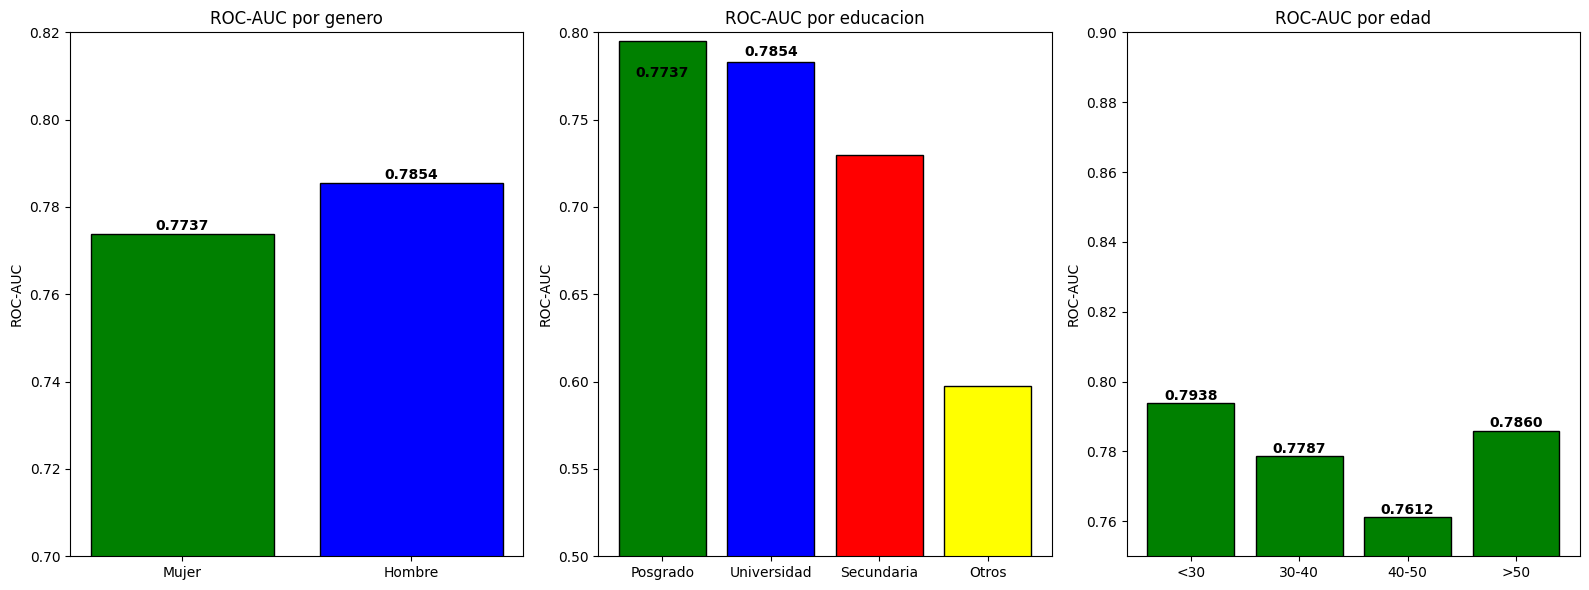

In [ ]:
fig, axes= plt.subplots(1,3, figsize=(16,6))

# por sexo
sexos=['Mujer','Hombre']
auc_sexo= [0.7737, 0.7854]
axes[0].bar(sexos,auc_sexo, color=['green','blue'], edgecolor='black')
axes[0].set_title('ROC-AUC por genero')
axes[0].set_ylim(0.70,0.82)
axes[0].set_ylabel('ROC-AUC')
for i, v in enumerate(auc_sexo):
  axes[0].text(i, v+0.001,f'{v:.4f}', ha='center',fontweight='bold')

# por educacion
educacion=['Posgrado','Universidad','Secundaria', 'Otros']
auc_edu= [0.7953, 0.7832, 0.7295, 0.5974]
colores_edu= ['green','blue','red','yellow']
axes[1].bar(educacion,auc_edu, color=colores_edu, edgecolor='black')
axes[1].set_title('ROC-AUC por educacion')
axes[1].set_ylim(0.50,0.80)
axes[1].set_ylabel('ROC-AUC')
for i, v in enumerate(auc_sexo):
  axes[1].text(i, v+0.001,f'{v:.4f}', ha='center',fontweight='bold')
# por edad
edades= ['<30','30-40','40-50','>50']
auc_edad=[0.7938, 0.7787, 0.7612, 0.7860]
axes[2].bar(edades,auc_edad, color='green', edgecolor='black')
axes[2].set_title('ROC-AUC por edad')
axes[2].set_ylim(0.75,0.90)
axes[2].set_ylabel('ROC-AUC')
for i, v in enumerate(auc_edad):
  axes[2].text(i, v+0.001,f'{v:.4f}', ha='center',fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:


df.to_csv('/content/drive/MyDrive/TFM/datos_historicos.csv', index=False)
X_test_sesgo.to_csv('/content/drive/MyDrive/TFM/datos_predicciones.csv', index=False)




In [ ]:
import snowflake.connector
from snowflake.connector.pandas_tools import write_pandas


In [ ]:
predicciones_upload = X_test_sesgo[['LIMIT_BAL', 'AGE', 'SEX', 'EDUCATION', 'MARRIAGE', 'y_pred', 'y_prob', 'y_real']].copy()
predicciones_upload = predicciones_upload.reset_index(drop=True)
predicciones_upload['RIESGO'] = predicciones_upload['y_pred'].map({0:'BAJO', 1:'ALTO'})
predicciones_upload = predicciones_upload.rename(columns={'y_pred': 'PREDICCION', 'y_prob': 'PROBABILIDAD_IMPAGO', 'y_real': 'Y_REAL'})
predicciones_upload = predicciones_upload[['LIMIT_BAL', 'AGE', 'SEX', 'EDUCATION', 'MARRIAGE', 'PREDICCION', 'PROBABILIDAD_IMPAGO', 'RIESGO', 'Y_REAL']]
success, nchunks, nrows, _ = write_pandas(conn=conn, df=predicciones_upload, table_name='PREDICCIONES', database='TFM_DB', schema='PUBLIC')



In [ ]:
print(X_test_sesgo.columns.tolist())

['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'ratio_uso_credito', 'total_deuda', 'total_pagado', 'ratio_pago_deuda', 'tendencia_pago', 'y_real', 'y_pred', 'y_prob', 'grupo_edad']


###

### Este notebook recoge el desarrollo completo del sistema de scoring de riesgo crediticio, en donde se incorporo:
- Interpretabilidad(SHAP) y analisis de equidad por genero, nivel educativo y edad(en donde no se encontraron diferencias significativas).
- Explicabilidad mediante IA Generativa(Gemini).
Productivizacion mediante API REST y una base de datos cloud.

El modelo final alcanza un ROC-AUC de 0,78, detectando el 61* de los clientes que efectivamente incurren en impago.

Para mayor profundidad, consultar la memoria del TFM que acompaña este notebook.